# Custom CNN (KneeCNN) trained from scratch

We train our own CNN, **KneeCNN**, from scratch. The code follows `02_transfer_learning.ipynb` (same sections, data code, training loop and plots), so both notebooks can be compared directly.

**Class imbalance:** as agreed in the team, we use **mild augmentation + weighted sampler** (the data method of `02_transfer_learning.ipynb`). The comparison of data methods is in `01_custom_cnn_comparison.ipynb`.

**In this notebook:**
**Round 2 only.** Round 1 (batch size and learning rate) was done in Colab; winner: **batch size 16, learning rate 0.0001** (validation AUROC 0.840). Its best epoch was always the last one, so we now train **20 epochs**.

1. Start from the winner of round 1 and try **dropout**, **weight decay** and **label smoothing**, compared on the **validation set**.
2. Use the best setting for the **final test** (only once).

Real run with `USE_SAMPLE_DATA = False` (Kaggle with a GPU). The sample data is not available in this Kaggle version (no GitHub clone).

**This is the Kaggle version of `01_custom_cnn.ipynb`.** The code is the same; only the paths and the setup are changed for Kaggle.

**Before you start (Kaggle settings, right side panel "Session options"):**
- **Accelerator:** `GPU T4 x2` (not P100: the newest PyTorch no longer supports the P100)
- **Internet:** not needed. This notebook does **not** clone GitHub; the only file we need from the repository (`src/metrics.py`, by Jobin) is written by the notebook itself.
- **Real data:** upload the `data` folder (with `train`, `val`, `test` inside) once as a **Kaggle Dataset**, then add it with **Add Input**. The notebook finds the folder by itself under `/kaggle/input`.
- **Time limit:** max. 12 hours per session, about 30 GPU hours per week. Click **Stop session** when you are done, so no GPU time is wasted.
- **Run time:** 6 trainings of 20 epochs each, roughly 1–2 hours on a T4 (estimate). Best way: **Save Version → Save & Run All (Commit)**. It runs in the background (you can close the browser) and keeps all outputs.
- ⚠️ "Run All" also runs section 7 (**test set**). That is fine for the final run; do not run it again afterwards to "improve" the result.
- **Saving results:** everything in `/kaggle/working` is lost when the session ends. Download the `output` folder before stopping (right panel → Output), or use **Save Version → Save & Run All**.

## Set up the project in Kaggle

Kaggle cannot always reach GitHub, so instead of `git clone` we create the project folder in `/kaggle/working` (the only folder we can write to) and write `src/metrics.py` into it.

- First cell: create the folder and go into it.
- Second cell: an **exact copy of `src/metrics.py`** from our repository (Jobin's metrics and plots). Do not change it here; changes belong in the repository.

In [5]:
# Run this cell FIRST: it creates the project folder (incl. src) and goes into it
!mkdir -p /kaggle/working/medical-image-classification/src
%cd /kaggle/working/medical-image-classification

/kaggle/working/medical-image-classification


In [6]:
%%writefile /kaggle/working/medical-image-classification/src/metrics.py
"""Framework-independent evaluation of 5-class Kellgren-Lawrence CNN predictions.

Dependencies: numpy, pandas, scikit-learn, matplotlib.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, roc_curve, cohen_kappa_score, mean_absolute_error)


def evaluate_predictions(y_true, y_prob=None, y_pred=None, *, model_name='cnn',
                         output_dir='metrics_output', class_names=None, logits=None, show_plots=True,save_plots=False):
    """Evaluate predictions; provide y_true and either y_prob, logits, or y_pred.

    y_true: shape (N,), integer labels 0..4.
    y_prob: shape (N,5), class probabilities in KL0..KL4 order.
    logits: shape (N,5), raw class scores (converted via softmax).
    y_pred: shape (N,), hard class predictions (AUROC unavailable without scores).
    """
    labels = np.arange(5)
    names = list(class_names) if class_names is not None else [f'KL{i}' for i in labels]
    if len(names) != 5:
        raise ValueError('class_names must contain exactly five names.')
    yt = np.asarray(y_true).reshape(-1)
    if yt.size == 0 or not np.all(np.isin(yt, labels)):
        raise ValueError('y_true must be a nonempty vector of KL labels 0..4.')
    if sum(v is not None for v in (y_prob, logits, y_pred)) != 1:
        raise ValueError('Supply exactly one of y_prob, logits, or y_pred.')
    probs = None
    if logits is not None:
        scores = np.asarray(logits, dtype=float)
        if scores.shape != (len(yt), 5) or not np.all(np.isfinite(scores)):
            raise ValueError('logits must be a finite N x 5 array.')
        shifted = scores - scores.max(axis=1, keepdims=True)
        exp = np.exp(shifted)
        probs = exp / exp.sum(axis=1, keepdims=True)
    elif y_prob is not None:
        probs = np.asarray(y_prob, dtype=float)
        if probs.shape != (len(yt), 5) or not np.all(np.isfinite(probs)):
            raise ValueError('y_prob must be a finite N x 5 array.')
        if np.any(probs < 0) or np.any(probs > 1) or not np.allclose(probs.sum(axis=1), 1, atol=1e-4):
            raise ValueError('Each probability row must sum to 1 and lie within [0,1].')
    yp = np.argmax(probs, axis=1) if probs is not None else np.asarray(y_pred).reshape(-1)
    if len(yp) != len(yt) or not np.all(np.isin(yp, labels)):
        raise ValueError('y_pred must match y_true length and contain labels 0..4.')

    if save_plots:
        out = Path(output_dir) / model_name
        out.mkdir(parents=True, exist_ok=True)
    precision, recall, f1, support = precision_recall_fscore_support(
        yt, yp, labels=labels, zero_division=0)
    per_class = pd.DataFrame({'class': names, 'precision': precision, 'recall': recall,
                              'f1': f1, 'support': support})
    aucs = []
    for k in labels:
        binary = (yt == k).astype(int)
        auc = float(roc_auc_score(binary, probs[:, k])) if (probs is not None and len(np.unique(binary)) == 2) else np.nan
        aucs.append(auc)
    per_class['auroc_ovr'] = aucs
    if save_plots:
        per_class.to_csv(out / 'per_class_metrics.csv', index=False)

    cm = confusion_matrix(yt, yp, labels=labels)
    def plot_cm(normalized):
        data = cm.astype(float)
        if normalized:
            denom = data.sum(axis=1, keepdims=True)
            data = np.divide(data, denom, out=np.zeros_like(data), where=denom != 0)
        fig, ax = plt.subplots(figsize=(7, 6))
        im = ax.imshow(data, cmap='Blues', vmin=0, vmax=1 if normalized else None)
        ax.set(xticks=range(5), yticks=range(5), xticklabels=names, yticklabels=names,
               xlabel='Predicted KL grade', ylabel='True KL grade',
               title='Normalized confusion matrix' if normalized else 'Confusion matrix')
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f'{data[i,j]:.2f}' if normalized else str(cm[i,j]),
                        ha='center', va='center', color='white' if data[i,j] > data.max()/2 else 'black')
        fig.colorbar(im, ax=ax)
        fig.tight_layout()
        #fig.savefig(out / ('normalized_confusion_matrix.png' if normalized else 'confusion_matrix.png'), dpi=180)
        if save_plots:
            filename = (
                'normalized_confusion_matrix.png'
                if normalized else 'confusion_matrix.png'
            )
            fig.savefig(out / filename, dpi=180)

        if show_plots:
            plt.show()

        plt.close(fig)
    plot_cm(False)
    plot_cm(True)

    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(5)
    for i, metric in enumerate(['precision', 'recall', 'f1']):
        ax.bar(x + (i-1)*0.25, per_class[metric], 0.25, label=metric)
    ax.set(xticks=x, xticklabels=names, ylim=(0, 1.05), ylabel='Score', title='Per-class classification metrics')
    ax.legend()
    fig.tight_layout()
    #fig.savefig(out / 'per_class_metrics.png', dpi=180)
    if save_plots:
        fig.savefig(out / 'per_class_metrics.png', dpi=180)

    if show_plots:
        plt.show()

    plt.close(fig)

    if probs is not None:
        fig, ax = plt.subplots(figsize=(7, 6))
        plotted = False
        for k, auc in enumerate(aucs):
            if np.isfinite(auc):
                fpr, tpr, _ = roc_curve((yt == k).astype(int), probs[:, k])
                ax.plot(fpr, tpr, label=f'{names[k]} (AUC={auc:.3f})')
                plotted = True
        if plotted:
            ax.plot([0, 1], [0, 1], '--', color='gray')
            ax.set(xlabel='False positive rate', ylabel='True positive rate', title='One-vs-rest ROC curves')
            ax.legend()
            fig.tight_layout()
            #fig.savefig(out / 'roc_curves.png', dpi=180)
            if save_plots:
                fig.savefig(out / 'roc_curves.png', dpi=180)

            if show_plots:
                plt.show()

        plt.close(fig)

    _, _, macro_f1, _ = precision_recall_fscore_support(yt, yp, labels=labels, average='macro', zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(yt, yp, labels=labels, average='weighted', zero_division=0)
    present_aucs = [a for a in aucs if np.isfinite(a)]
    results = {
        'model_name': model_name, 'n_samples': int(len(yt)),
        'accuracy': float(accuracy_score(yt, yp)),
        'balanced_accuracy': float(balanced_accuracy_score(yt, yp)),
        'macro_f1': float(macro_f1), 'weighted_f1': float(weighted_f1),
        'quadratic_weighted_kappa': float(cohen_kappa_score(yt, yp, labels=labels, weights='quadratic')),
        'mae': float(mean_absolute_error(yt, yp)),
        'macro_auroc_ovr': float(np.mean(present_aucs)) if len(present_aucs) == 5 else None,
    }
    if save_plots:
        with open(out / 'metrics.json', 'w') as f:
            json.dump(results, f, indent=2, allow_nan=False)
    return results


def plot_training_history(history,*,model_name='cnn',output_dir='metrics_output',show_plots=True,save_plots=False):
    """
    Plot training and validation accuracy/loss curves.

    show_plots=True  -> Display graphs in Jupyter notebook.
    save_plots=True  -> Save graphs as PNG files.
    """

    if not isinstance(history, list) or not history:
        raise ValueError('history must be a nonempty list of per-epoch dictionaries.')

    keys = ('train_accuracy', 'val_accuracy', 'train_loss', 'val_loss')

    try:
        data = {
            k: np.asarray([row[k] for row in history], dtype=float)
            for k in keys
        }
        epochs = np.asarray(
            [row['epoch'] for row in history], dtype=float
        )

    except (KeyError, TypeError, ValueError) as exc:
        raise ValueError(
            'Each epoch must contain epoch, train_accuracy, '
            'val_accuracy, train_loss, val_loss.'
        ) from exc

    if not np.all(np.isfinite(epochs)) or any(
        not np.all(np.isfinite(v)) for v in data.values()
    ):
        raise ValueError(
            'Epochs, accuracy and loss values must be finite.'
        )

    # Create output folder only when saving
    if save_plots:
        out = Path(output_dir) / model_name
        out.mkdir(parents=True, exist_ok=True)

    saved = {}

    for metric, ylabel in [('accuracy', 'Accuracy'), ('loss', 'Loss')]:

        fig, ax = plt.subplots(figsize=(8, 5))

        ax.plot(
            epochs,
            data[f'train_{metric}'],
            label=f'Training {metric}'
        )

        ax.plot(
            epochs,
            data[f'val_{metric}'],
            label=f'Validation {metric}'
        )

        ax.set(
            xlabel='Epoch',
            ylabel=ylabel,
            title=f'{model_name}: Training and Validation {metric}'
        )

        ax.legend()
        ax.grid(alpha=0.25)
        fig.tight_layout()

        # Optional saving
        if save_plots:
            filename = out / f'training_validation_{metric}.png'
            fig.savefig(filename, dpi=180, bbox_inches='tight')
            saved[metric] = str(filename)

        # Optional display in notebook
        if show_plots:
            display(fig)

        plt.close(fig)

    return saved

Overwriting /kaggle/working/medical-image-classification/src/metrics.py


In [8]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Set paths
# NEW: True = 150 sample X-rays (quick test), False = real dataset
USE_SAMPLE_DATA = False

if USE_SAMPLE_DATA:
    DATA_DIR = Path('/kaggle/working/medical-image-classification/example_data/knee_oa_test')
    if not DATA_DIR.exists():
        import zipfile
        zipfile.ZipFile('/kaggle/working/medical-image-classification/example_data/knee_oa_test.zip').extractall('/kaggle/working/medical-image-classification/example_data')
    # The sample zip was made on a Mac: delete the hidden "._" files, they are not images
    for mac_file in DATA_DIR.rglob('._*'):
        mac_file.unlink()
else:
    # Kaggle: added datasets are in /kaggle/input (read-only).
    # Find the folder that contains train, val and test.
    DATA_DIR = None
    for folder in sorted(Path('/kaggle/input').rglob('train')):
        if '__MACOSX' in folder.parts:   # hidden Mac copy, not real images
            continue
        if (folder.parent / 'val').is_dir() and (folder.parent / 'test').is_dir():
            DATA_DIR = folder.parent
            break
    if DATA_DIR is None:
        raise FileNotFoundError("No folder with train/val/test found in /kaggle/input. "
                                "Add your dataset with 'Add Input' first.")
OUTPUT_DIR = Path('/kaggle/working/medical-image-classification/output')

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Set DATA_DIR to your actual dataset folder first: {DATA_DIR}")
print('Dataset path:', DATA_DIR.resolve())

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Dataset path: /kaggle/input/datasets/alisabitschnau/data-cnn/data


## 1. Load and inspect data

The dataset already split the data into `train`, `test` and `val` folders. The same label mapping and normalization will be used by every model. The number of images between classes varies a lot. To handle this we use **mild augmentation** of every training image (rotation ±5°, left–right flip, ±5 % brightness/contrast) and a **weighted sampler** that draws rare grades more often – the same data code as in `02_transfer_learning.ipynb`. Validation and test images are never augmented.

`make_loaders(batch_size)` builds the loaders, so we can try different batch sizes.

In [9]:
from torchvision.datasets.folder import default_loader

# Normalization matches common ImageNet-pretrained ResNet/EfficientNet weights.
# Keep these choices the same in all experiments.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

IMAGE_SIZE = 224
NUM_CLASSES = 5

class ImageSubset(Dataset):
    """ImageFolder-compatible subset that stores explicit (path, label) entries."""
    def __init__(self, samples, transform):
        self.samples = [(str(p), int(y)) for p, y in samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = default_loader(path)  # RGB
        return self.transform(img), label

# Load datasets
train_source = datasets.ImageFolder(DATA_DIR / 'train')
val_source = datasets.ImageFolder(DATA_DIR / 'val')
test_source = datasets.ImageFolder(DATA_DIR / 'test')

split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }

class_names = train_source.classes

# Mild augmentation for knee X-rays
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# No random augmentation for validation/test
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_dataset = ImageSubset(
    split_samples["train"],
    train_transform
)

val_dataset = ImageSubset(
    split_samples["val"],
    base_transform
)

test_dataset = ImageSubset(
    split_samples["test"],
    base_transform
)

# Build weighted sampler from original training labels
labels = np.array([
    label for _, label in split_samples["train"]
])

counts = np.bincount(labels, minlength=NUM_CLASSES)

# Softer balancing than 1/count
alpha = 1
class_weights = 1.0 / (counts ** alpha)
sample_weights = class_weights[labels]


def make_loaders(batch_size):
    """Train/val/test loaders as in 02_transfer_learning.ipynb, for a given batch size."""
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(
            sample_weights,
            dtype=torch.double
        ),
        num_samples=len(labels),
        replacement=True
    )

    return {
        "train": DataLoader(
            train_dataset,
            batch_size=batch_size,
            sampler=sampler,
            pin_memory=(DEVICE.type == "cuda")
        ),
        "val": DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(DEVICE.type == "cuda")
        ),
        "test": DataLoader(
            test_dataset,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(DEVICE.type == "cuda")
        )
    }


print("Original class counts:", counts)
print("Class sampling weights:", class_weights)

Original class counts: [2286 1046 1516  757  173]
Class sampling weights: [0.00043745 0.00095602 0.00065963 0.001321   0.00578035]


## 2. Custom CNN trained from scratch

Unlike ResNet-18 and EfficientNet-B0, KneeCNN starts with random weights: all layers are trained, no freezing.

### 2.1 Set Training parameters

Each run is described by five settings. `BASE` is the starting point; every line in a round changes **one** setting, so we can see what each change does. Each line is one full training (`NUM_EPOCHS = 10`) – remove lines to save time.

- `batch_size` – images per learning step
- `lr` – learning rate (size of each correction step)
- `dropout` – share of features switched off during training (against overfitting)
- `weight_decay` – pulls weights gently toward 0 (against overfitting)
- `label_smoothing` – makes the model less overconfident (0 = off, 0.1 = the correct grade gets 90 % instead of 100 % as target)

**Tune in two rounds:**
1. **Round 1 (done in Colab):** batch size and learning rate → winner: batch size 16, learning rate 0.0001.
2. **Round 2 (this notebook):** `BASE` = winner of round 1, trained again with 20 epochs for a fair comparison; every other line changes dropout, weight decay or label smoothing.

In [10]:
# Winner of round 1 (Colab): batch size 16, learning rate 0.0001
BASE = dict(batch_size=16, lr=1e-4, dropout=0.5, weight_decay=1e-4, label_smoothing=0.0)

# ---- Round 2: dropout, weight decay, label smoothing ----
ROUND_2 = [
    BASE,                                # winner of round 1 (again, with 20 epochs, for a fair comparison)
    {**BASE, 'dropout': 0.3},            # less dropout
    {**BASE, 'dropout': 0.6},            # more dropout
    {**BASE, 'weight_decay': 1e-5},      # weaker weight decay
    {**BASE, 'weight_decay': 1e-3},      # stronger weight decay
    {**BASE, 'label_smoothing': 0.1},    # label smoothing
]

NUM_EPOCHS = 20   # was 10: in round 1 the best epoch was always the last one
NUM_CLASSES = 5
criterion = nn.CrossEntropyLoss()

def config_name(c):
    """Short name of a run, e.g. bs16_lr0.001_do0.5_wd0.0001_ls0"""
    return (f"bs{c['batch_size']}_lr{c['lr']:g}_do{c['dropout']:g}"
            f"_wd{c['weight_decay']:g}_ls{c['label_smoothing']:g}")

CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Training history of every run, by run name
histories = {}

Function to run training loop:

In [12]:
def run_epoch(model, loader, optimizer=None, epoch=None, num_epochs=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, correct, count = 0.0, 0, 0

    phase = "Train" if is_training else "Validate"
    description = f"Epoch [{epoch}/{num_epochs}] | {phase}"

    with tqdm(loader, leave=False, desc=description) as progressbar:
      for x, y in progressbar:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(x)
            loss = criterion(logits, y)

            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)

        progressbar.set_postfix(
            loss=f"{total_loss / count:.4f}",
            acc=f"{correct / count:.2%}"
        )

    return {'loss': total_loss / count, 'accuracy': correct / count}

### 2.2 KneeCNN
Our custom CNN instead of a pretrained model: 5 blocks (Conv → BatchNorm → ReLU, twice, then MaxPool), average pooling, dropout and one linear layer with 5 outputs (no softmax). About 2.36 million learnable parameters.

In [13]:
def conv_block(in_ch, out_ch):
    """Two 3x3 convolutions with BatchNorm + ReLU, then halve the image size."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class KneeCNN(nn.Module):
    """Custom CNN trained from scratch. Input: 3x224x224 image, output: one score per grade."""

    def __init__(self, n_classes, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),     # 224 -> 112
            conv_block(32, 64),    # 112 -> 56
            conv_block(64, 128),   # 56  -> 28
            conv_block(128, 256),  # 28  -> 14
            conv_block(256, 256),  # 14  -> 7
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),   # raw scores, no softmax
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print('Learnable parameters:', sum(p.numel() for p in KneeCNN(NUM_CLASSES).parameters()))

Learnable parameters: 2355173


## 2.2.1 Training + validation loops

The same training loop as for ResNet-18 in `02_transfer_learning.ipynb` (AdamW, learning-rate scheduler, early stopping, best model saved), run once per setting of a round. The loop is inside the function `train_runs`.

**One change:** the best epoch and early stopping use the **validation AUROC** instead of the validation loss. Reason: with the weighted sampler the model predicts the rare grades more often, which raises the validation loss even when the model gets better. With the loss, runs stopped after 5 epochs and kept the epoch-1 model. Before each run the seed is reset, so every run starts from the same random model.


========== bs16_lr0.0001_do0.5_wd0.0001_ls0 ==========


Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.6223 | Train Acc: 21.44% | Val Loss: 1.4293 | Val Acc: 37.65% | Val AUROC: 0.6534


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [19/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [19/20] | Train Loss: 0.6170 | Train Acc: 72.95% | Val Loss: 0.9176 | Val Acc: 59.08% | Val AUROC: 0.8683


Epoch [20/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [20/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [20/20] | Train Loss: 0.6239 | Train Acc: 72.71% | Val Loss: 0.9060 | Val Acc: 61.99% | Val AUROC: 0.8756


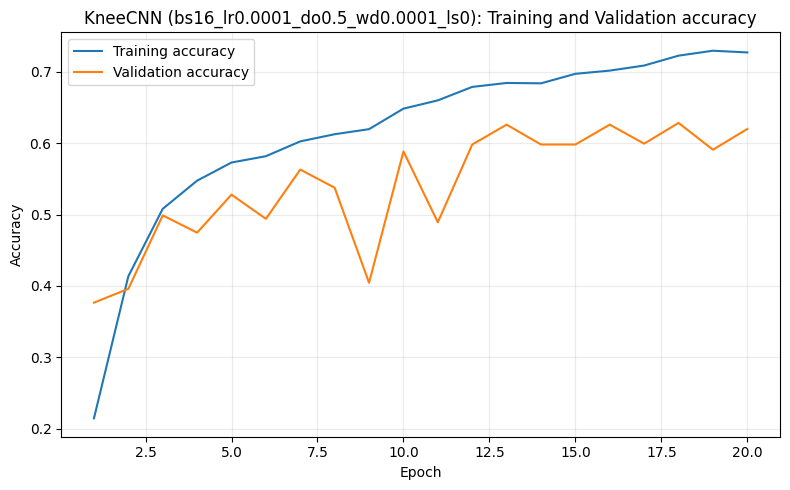

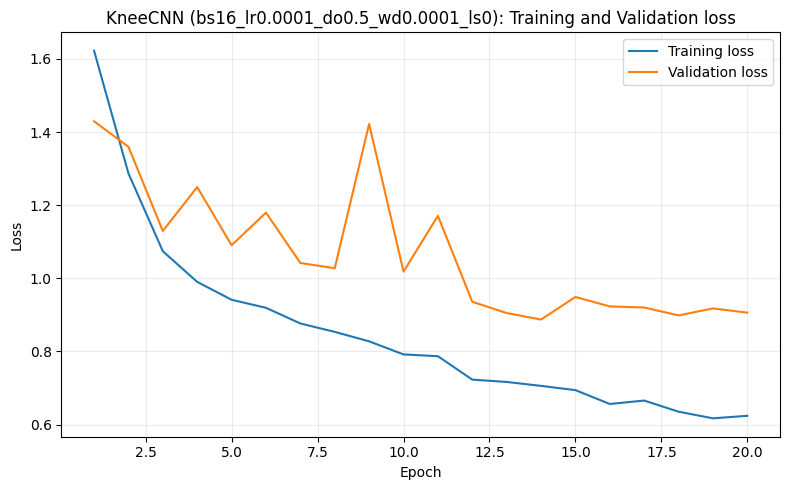


========== bs16_lr0.0001_do0.3_wd0.0001_ls0 ==========


Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.5941 | Train Acc: 23.71% | Val Loss: 1.4057 | Val Acc: 38.26% | Val AUROC: 0.6644


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [17/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [17/20] | Train Loss: 0.6499 | Train Acc: 71.56% | Val Loss: 0.9580 | Val Acc: 58.60% | Val AUROC: 0.8635


Epoch [18/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [18/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [18/20] | Train Loss: 0.6192 | Train Acc: 72.67% | Val Loss: 0.9058 | Val Acc: 63.32% | Val AUROC: 0.8739
Early stopping triggered!


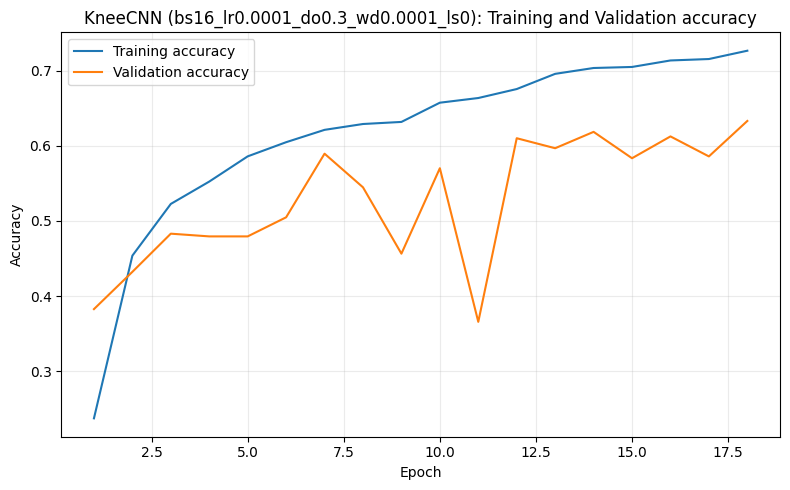

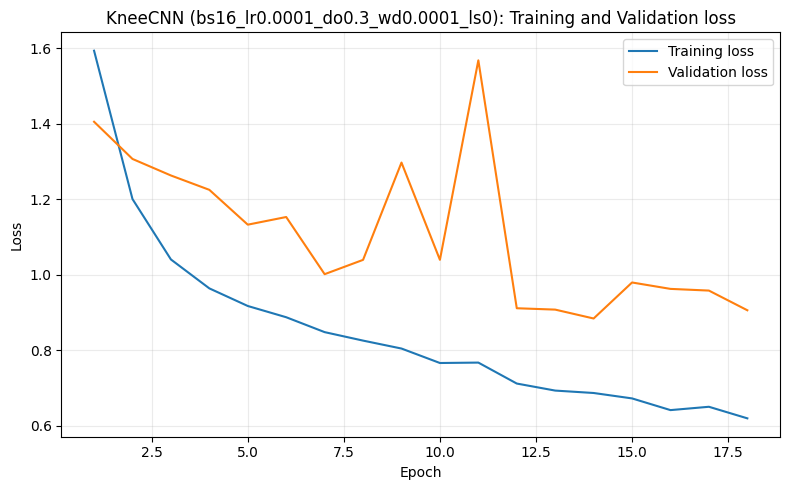


========== bs16_lr0.0001_do0.6_wd0.0001_ls0 ==========


Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.6319 | Train Acc: 21.98% | Val Loss: 1.4858 | Val Acc: 25.54% | Val AUROC: 0.6364


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [17/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [17/20] | Train Loss: 0.6877 | Train Acc: 69.42% | Val Loss: 0.9048 | Val Acc: 62.47% | Val AUROC: 0.8734


Epoch [18/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [18/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [18/20] | Train Loss: 0.6599 | Train Acc: 70.35% | Val Loss: 0.8880 | Val Acc: 63.32% | Val AUROC: 0.8749
Early stopping triggered!


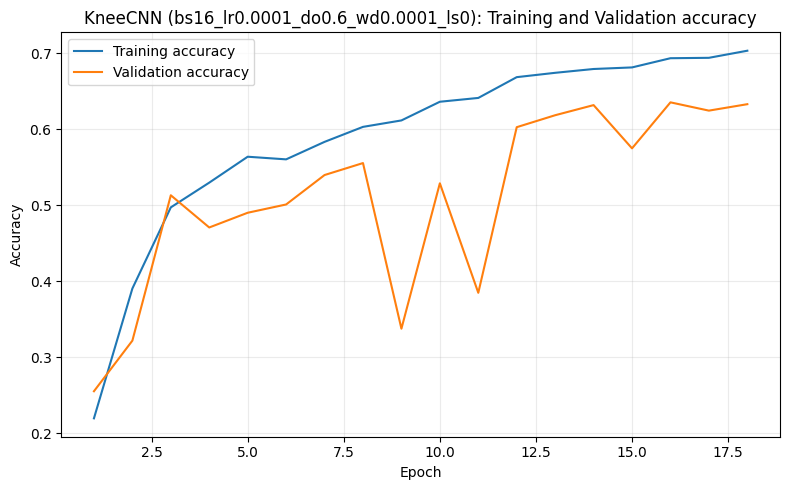

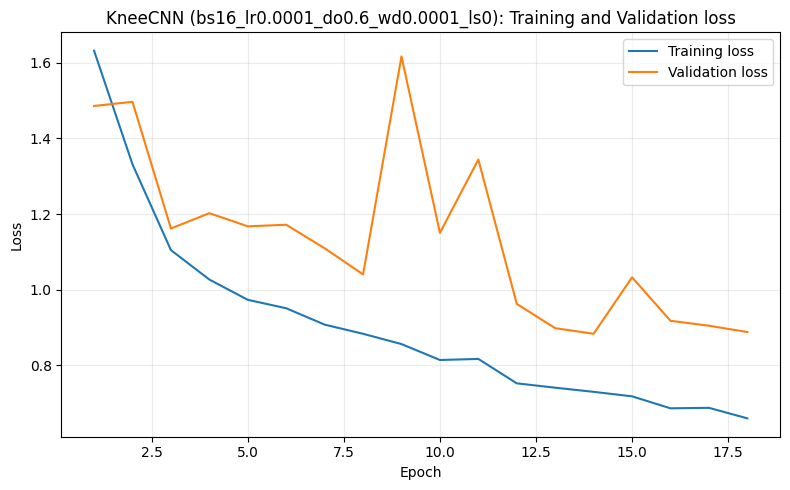


========== bs16_lr0.0001_do0.5_wd1e-05_ls0 ==========


Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.6177 | Train Acc: 22.24% | Val Loss: 1.4159 | Val Acc: 38.74% | Val AUROC: 0.6546


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [19/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [19/20] | Train Loss: 0.6324 | Train Acc: 71.70% | Val Loss: 0.8784 | Val Acc: 64.29% | Val AUROC: 0.8764


Epoch [20/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [20/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [20/20] | Train Loss: 0.6343 | Train Acc: 72.07% | Val Loss: 0.9538 | Val Acc: 60.17% | Val AUROC: 0.8767


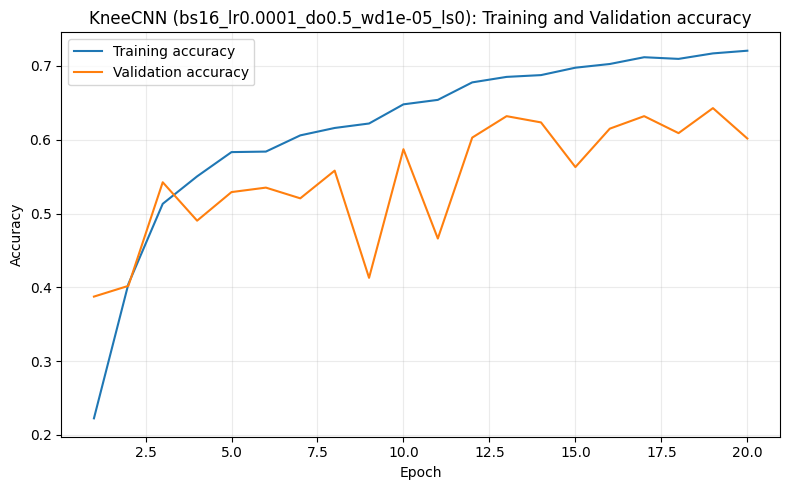

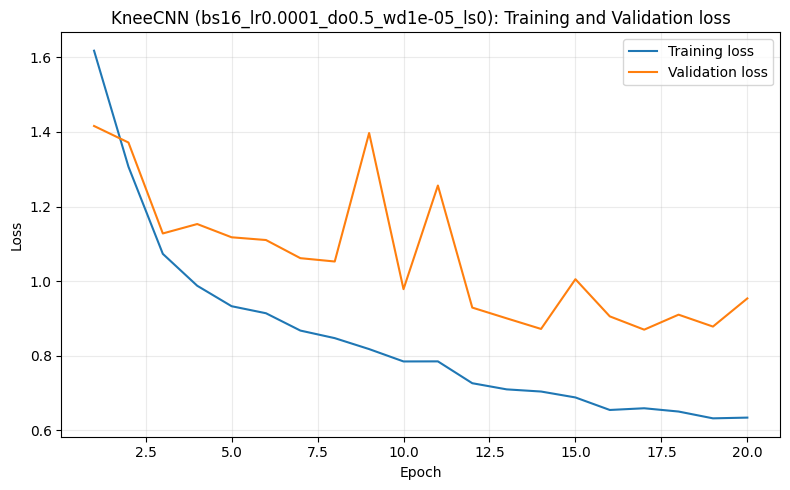


========== bs16_lr0.0001_do0.5_wd0.001_ls0 ==========


Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.6206 | Train Acc: 21.46% | Val Loss: 1.4014 | Val Acc: 38.38% | Val AUROC: 0.6504


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [17/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [17/20] | Train Loss: 0.6720 | Train Acc: 70.89% | Val Loss: 0.9196 | Val Acc: 59.32% | Val AUROC: 0.8713


Epoch [18/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [18/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [18/20] | Train Loss: 0.6401 | Train Acc: 71.84% | Val Loss: 0.8963 | Val Acc: 62.71% | Val AUROC: 0.8723
Early stopping triggered!


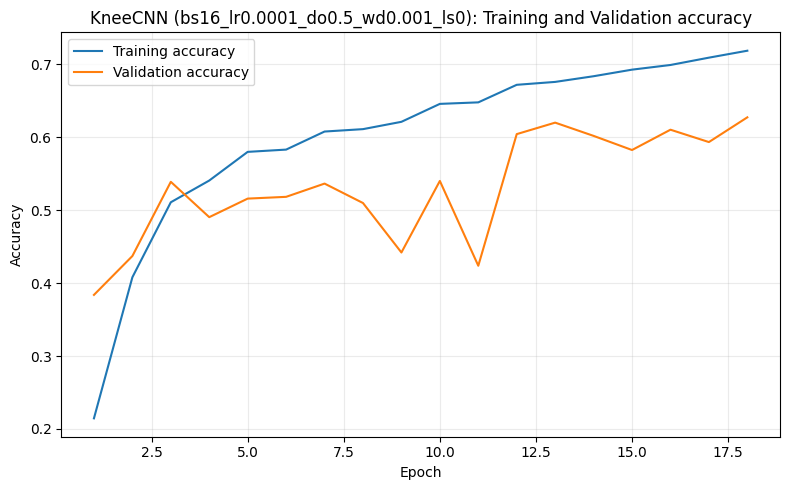

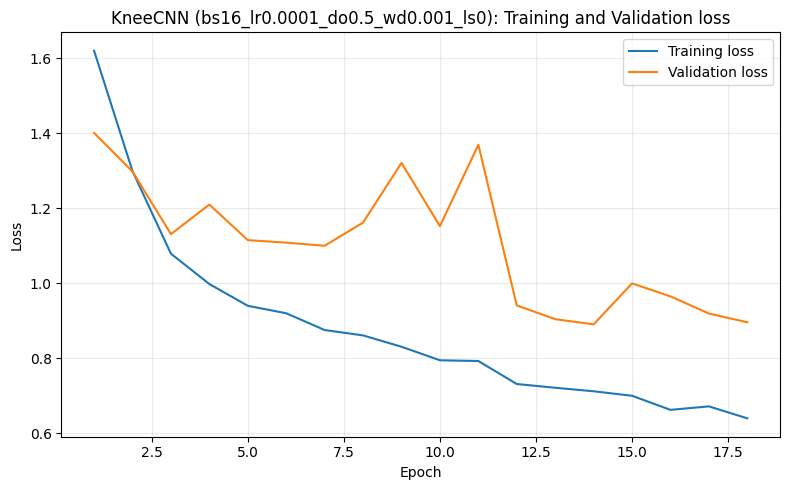


========== bs16_lr0.0001_do0.5_wd0.0001_ls0.1 ==========


Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.6304 | Train Acc: 21.06% | Val Loss: 1.5060 | Val Acc: 35.96% | Val AUROC: 0.6036


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [17/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [17/20] | Train Loss: 0.9191 | Train Acc: 70.66% | Val Loss: 1.0805 | Val Acc: 61.14% | Val AUROC: 0.8683


Epoch [18/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [18/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [18/20] | Train Loss: 0.8959 | Train Acc: 71.67% | Val Loss: 1.0777 | Val Acc: 61.38% | Val AUROC: 0.8697
Early stopping triggered!


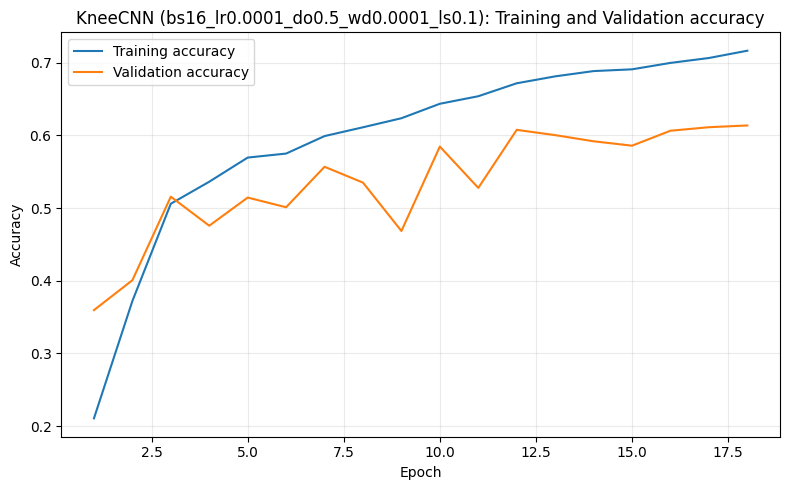

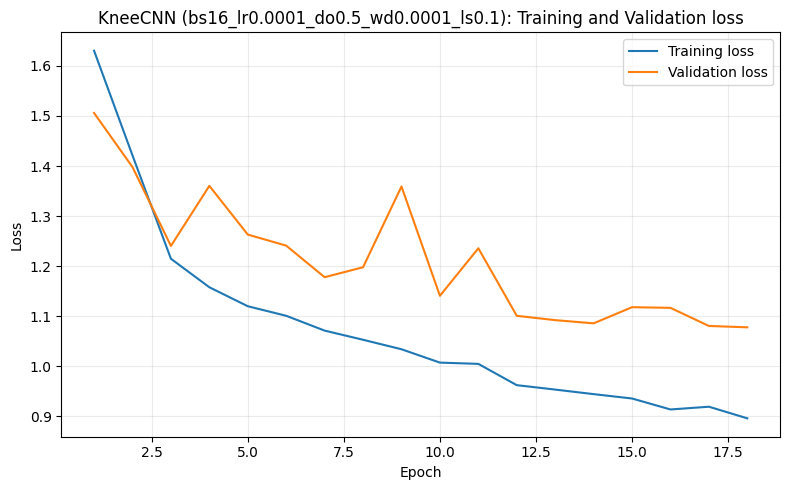

In [14]:
from src.metrics import plot_training_history

# Gives the true grades and the predicted probabilities (softmax) for one loader
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    actual, probs = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        actual.append(y.numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(actual), np.concatenate(probs)

def train_runs(configs):
    """Train KneeCNN once per setting in configs."""
    global criterion   # run_epoch uses the criterion set below
    for config in configs:
        run_name = config_name(config)
        print(f"\n========== {run_name} ==========")

        # Loss for this run (label smoothing 0 = normal cross-entropy); run_epoch uses "criterion"
        criterion = nn.CrossEntropyLoss(label_smoothing=config['label_smoothing'])

        # Same start for every run
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        loaders = make_loaders(config['batch_size'])

        # Create KneeCNN with 5 output classes and move it to the gpu
        model = KneeCNN(NUM_CLASSES, dropout=config['dropout']).to(DEVICE)

        # Train all parameters (no pretrained layers to freeze)
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=config['lr'],
            weight_decay=config['weight_decay']
        )

        history = []
        best_val_auroc = -1.0
        # Stops model after 4 epochs of not improving validation AUROC
        early_stop_rate = 4
        epochs_without_improvement = 0
        # Reduce learning rate when validation AUROC stagnates ("max" = higher is better)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=2
        )

        for epoch in range(1, NUM_EPOCHS + 1):
            train_stats = run_epoch(
                model, loaders['train'], optimizer,
                epoch=epoch, num_epochs=NUM_EPOCHS
            )

            val_stats = run_epoch(
                model, loaders['val'],
                epoch=epoch, num_epochs=NUM_EPOCHS
            )

            # Validation AUROC of this epoch
            y_val, val_prob = get_predictions(model, loaders['val'])
            val_auroc = roc_auc_score(y_val, val_prob, multi_class='ovr', average='macro')

            history.append({
              'epoch': epoch,
              'train_loss': train_stats['loss'],
              'train_accuracy': train_stats['accuracy'],
              'val_loss': val_stats['loss'],
              'val_accuracy': val_stats['accuracy'],
              'val_auroc': val_auroc
            })

            tqdm.write(
              f"Epoch [{epoch}/{NUM_EPOCHS}] | "
              f"Train Loss: {train_stats['loss']:.4f} | "
              f"Train Acc: {train_stats['accuracy']:.2%} | "
              f"Val Loss: {val_stats['loss']:.4f} | "
              f"Val Acc: {val_stats['accuracy']:.2%} | "
              f"Val AUROC: {val_auroc:.4f}"
            )

            scheduler.step(val_auroc)

            # Save the model if validation AUROC improved, otherwise count
            if val_auroc > best_val_auroc:
                best_val_auroc = val_auroc
                epochs_without_improvement = 0
                # Save best model
                torch.save(model.state_dict(), CHECKPOINT_DIR / f"best_kneecnn_{run_name}.pth")
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= early_stop_rate:
                print("Early stopping triggered!")
                break

        histories[run_name] = history

        # Plot training metrics over epochs
        plot_training_history(
            history,
            output_dir=OUTPUT_DIR / "metrics",
            model_name=f"KneeCNN ({run_name})",
            show_plots = True,
            save_plots = False
        )

# ---- Round 2 ----
train_runs(ROUND_2)

## 2.2.2 Validation predictions and metrics

Each run's best model (highest validation AUROC) is tested on the validation set. AUROC is calculated as in `02_transfer_learning.ipynb`: softmax probabilities, one-vs-rest per grade, macro average.

`best_val_loss` is not comparable between runs with and without label smoothing (smoothing raises the loss), so we compare the runs with the AUROC.

The table also shows how well each run handles the difficult grades: **balanced accuracy**, **macro F1** and the **recall of KL1, KL2 and KL4** (share of real KL1/KL2/KL4 knees that were found). The run with the highest validation AUROC is used for the final test.

In [15]:
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

def summarize_metrics(y_true, probabilities, class_names):
    predictions = probabilities.argmax(axis=1)
    results = {'accuracy': accuracy_score(y_true, predictions)}
    present = np.unique(y_true)
    if len(class_names) == 2 and len(present) == 2:
        results['auroc'] = roc_auc_score(y_true, probabilities[:, 1])
    elif len(present) == len(class_names):
        results['auroc'] = roc_auc_score(
            y_true, probabilities, labels=np.arange(len(class_names)),
            multi_class='ovr', average='macro')
    else:
        results['auroc'] = float('nan')
        print('AUROC undefined: not all classes appear in this validation split.')
    return results, confusion_matrix(y_true, predictions,
                                      labels=np.arange(len(class_names)))

def compare_runs(configs):
    """Validation metrics of the best model of every run in configs (one table row per run)."""
    comparison = []
    for config in configs:
        run_name = config_name(config)
        model = KneeCNN(NUM_CLASSES, dropout=config['dropout']).to(DEVICE)
        model.load_state_dict(torch.load(CHECKPOINT_DIR / f"best_kneecnn_{run_name}.pth",
                                         map_location=DEVICE, weights_only=True))

        y_val, val_prob = get_predictions(model, make_loaders(config['batch_size'])['val'])
        val_pred = val_prob.argmax(axis=1)
        metrics, cm = summarize_metrics(y_val, val_prob, class_names)
        print(f'\n===== {run_name} =====')
        print('Validation metrics:', metrics)
        print('Confusion matrix (rows=true, cols=predicted):')
        display(pd.DataFrame(cm, index=class_names, columns=class_names))

        recall = recall_score(y_val, val_pred, labels=np.arange(NUM_CLASSES), average=None, zero_division=0)
        comparison.append({
            'run': run_name,
            **config,
            'val_auroc': metrics['auroc'],
            'val_accuracy': metrics['accuracy'],
            'val_balanced_accuracy': balanced_accuracy_score(y_val, val_pred),
            'val_macro_f1': f1_score(y_val, val_pred, average='macro', zero_division=0),
            'recall_KL1': recall[1],
            'recall_KL2': recall[2],
            'recall_KL4': recall[4],
            'best_epoch': max(histories[run_name], key=lambda h: h['val_auroc'])['epoch'],
            'epochs_run': len(histories[run_name]),
        })
    return pd.DataFrame(comparison)


# ---- Round 2 ----
comparison = compare_runs(ROUND_2).sort_values('val_auroc', ascending=False).reset_index(drop=True)
display(comparison.round(4))

BEST_RUN = comparison.loc[0, 'run']
BEST_CONFIG = next(c for c in ROUND_2 if config_name(c) == BEST_RUN)
BEST_BATCH_SIZE = BEST_CONFIG['batch_size']
print('Best setting (highest validation AUROC):', BEST_RUN)

best_model = KneeCNN(NUM_CLASSES, dropout=BEST_CONFIG['dropout']).to(DEVICE)
best_model.load_state_dict(torch.load(CHECKPOINT_DIR / f"best_kneecnn_{BEST_RUN}.pth",
                                      map_location=DEVICE, weights_only=True))


===== bs16_lr0.0001_do0.5_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.6198547215496368, 'auroc': np.float64(0.8756221006042899)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,237,77,9,4,1
1,57,70,22,4,0
2,26,69,103,14,0
3,1,5,18,78,4
4,0,0,0,3,24



===== bs16_lr0.0001_do0.3_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.6186440677966102, 'auroc': np.float64(0.8748348832823997)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,217,93,14,2,2
1,47,77,26,3,0
2,19,64,118,11,0
3,0,6,22,77,1
4,0,0,0,5,22



===== bs16_lr0.0001_do0.6_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.6319612590799032, 'auroc': np.float64(0.8765406913691853)}
Confusion matrix (rows=true, cols=predicted):


...


===== bs16_lr0.0001_do0.5_wd0.0001_ls0.1 =====
Validation metrics: {'accuracy': 0.5920096852300242, 'auroc': np.float64(0.8730240100207931)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,188,118,16,5,1
1,46,75,27,5,0
2,12,60,121,19,0
3,1,4,16,81,4
4,0,0,0,3,24


,run,batch_size,lr,dropout,weight_decay,label_smoothing,val_auroc,val_accuracy,val_balanced_accuracy,val_macro_f1,recall_KL1,recall_KL2,recall_KL4,best_epoch,epochs_run
0,bs16_lr0.0001_do0.5_wd1e-05_ls0,16,0.0001,0.5,0.0000,0.0,0.8767,0.6017,0.6431,0.6312,0.5033,0.2972,0.8889,20,20
1,bs16_lr0.0001_do0.6_wd0.0001_ls0,16,0.0001,0.6,0.0001,0.0,0.8765,0.6320,0.6624,0.6686,0.4706,0.5189,0.8519,14,18
2,bs16_lr0.0001_do0.5_wd0.0001_ls0,16,0.0001,0.5,0.0001,0.0,0.8756,0.6199,0.6581,0.6548,0.4575,0.4858,0.8889,20,20
3,bs16_lr0.0001_do0.3_wd0.0001_ls0,16,0.0001,0.3,0.0001,0.0,0.8748,0.6186,0.6525,0.6611,0.5033,0.5566,0.8148,14,18
4,bs16_lr0.0001_do0.5_wd0.0001_ls0.1,16,0.0001,0.5,0.0001,0.1,0.8730,0.5920,0.6574,0.6468,0.4902,0.5708,0.8889,14,18
5,bs16_lr0.0001_do0.5_wd0.001_ls0,16,0.0001,0.5,0.0010,0.0,0.8727,0.6017,0.6465,0.6581,0.5098,0.5094,0.8148,14,18


Best setting (highest validation AUROC): bs16_lr0.0001_do0.5_wd1e-05_ls0


<All keys matched successfully>

## **7**. Detailed CNN evaluation

⚠️ This uses the **test set**: run it only once, with the best setting from 2.2.2.

Current backend: module://matplotlib_inline.backend_inline
True labels: (1656,)
Predicted probabilities: (1656, 5)


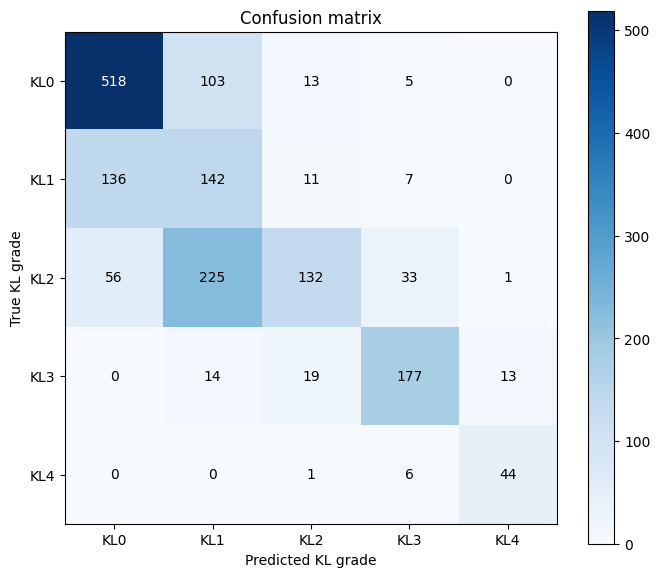

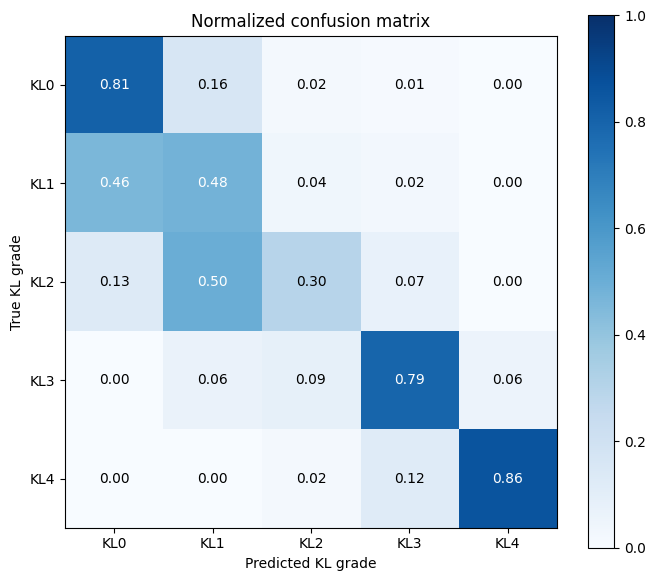

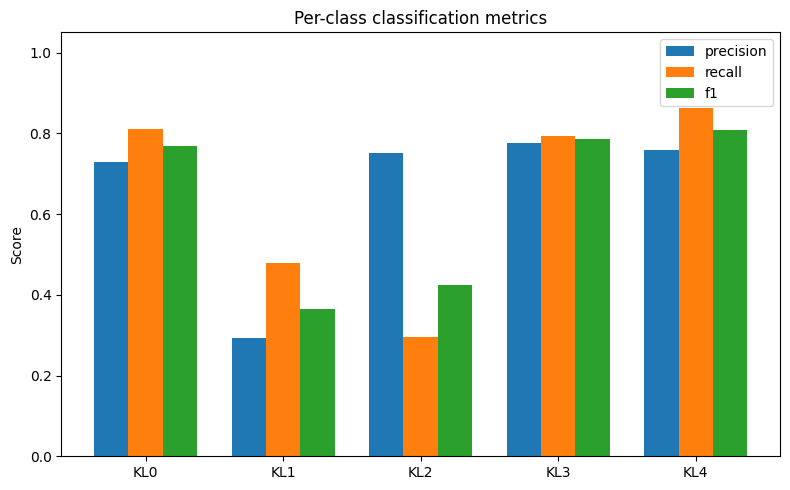

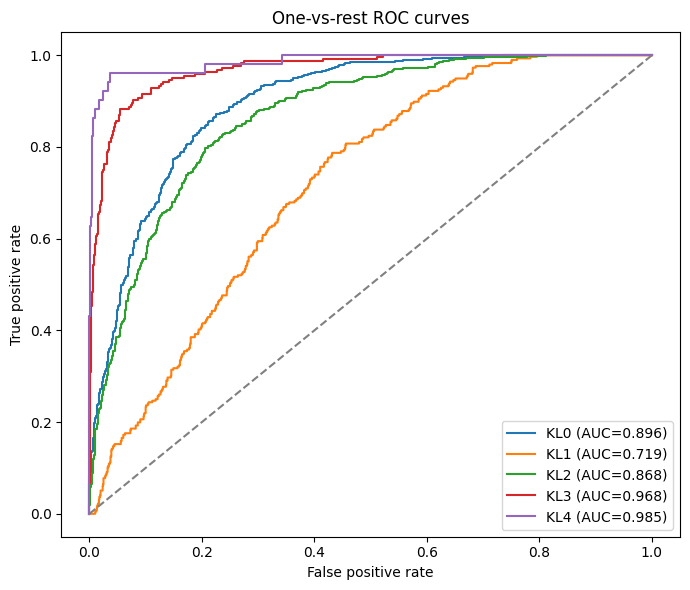

{'model_name': 'KneeCNN (bs16_lr0.0001_do0.5_wd1e-05_ls0)', 'n_samples': 1656, 'accuracy': 0.6117149758454107, 'balanced_accuracy': 0.6484280883657941, 'macro_f1': 0.6296193412617919, 'weighted_f1': 0.6063660311772241, 'quadratic_weighted_kappa': 0.7963825132240128, 'mae': 0.4498792270531401, 'macro_auroc_ovr': 0.8873929420040859}


In [18]:
import matplotlib
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")

print("Current backend:", matplotlib.get_backend())

# Generate predictions
y_test, test_prob = get_predictions(best_model, make_loaders(BEST_BATCH_SIZE)["test"])

print("True labels:", y_test.shape)
print("Predicted probabilities:", test_prob.shape)

from src.metrics import evaluate_predictions

# Evaluate CNN performance
results = evaluate_predictions(
    y_true=y_test,
    y_prob=test_prob,
    model_name=f"KneeCNN ({BEST_RUN})",
    show_plots=True,
    save_plots=False
)

print(results)

## 9. Optional: save a checkpoint

Saves the best model with its settings to `OUTPUT_DIR`. In Kaggle, `/kaggle/working` is emptied when the session ends: download the file afterwards. Do not upload model files to GitHub.

In [ ]:
SAVE_CHECKPOINT = False  # Change to True to save the best model
if SAVE_CHECKPOINT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint_file = OUTPUT_DIR / f'kneecnn_{BEST_RUN}.pt'
    torch.save({
        'model_state_dict': best_model.state_dict(),
        'settings': BEST_CONFIG,
        'class_names': class_names,
        'image_size': IMAGE_SIZE,
        'normalization_mean': MEAN,
        'normalization_std': STD,
        'seed': SEED,
        'history': histories[BEST_RUN],
    }, checkpoint_file)
    print('Saved:', checkpoint_file)
else:
    print('Checkpoint not saved; set SAVE_CHECKPOINT=True to enable.')